<a href="https://colab.research.google.com/github/jiraroj-wir/MUIC-ICCS261-Principles-of-Data-Science/blob/main/cs261_integrating_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integrating Data

Written by K. Bunchongchit <kritya.bun@mahidol.ac.th>

Last modified by Jiraroj Wiruchpongsanon (6781617) on 12/10/2026 

The World Population data file used in the previous assignment has the data about the total population, but not the poplulation density. Assume that your research team needed to investigate if the population density of a country has something to do with the level of income. As the data engineer of this research team, deliver the dataset that may provide your team with this answer. Once you have the prepared dataset as guided in Steps 1-11. Try to answer the research question in Step 12 as a glimpse into data visualization.

<b>The data files that you need to combine are already in this [data folder](https://drive.google.com/drive/folders/1SKGedyYv6KXxUZ4hsc95HMu4cfG6jCz2?usp=sharing).</b> I have done the initial preparation so that they can be loaded with the <code>read_csv</code> methods. However, if you need a small challenge into the real world data, you can get the files as is from the links below.

> Do not download data from here. The links will be given in cells below.
**Data sources**: [World Bank Open Data](https://data.worldbank.org) (<strong>cannot be opened</strong> right away with <code>pandas.read_csv</code>)
- [Population, total](https://data.worldbank.org/indicator/SP.POP.TOTL)
- [Land area (sq. km)](https://data.worldbank.org/indicator/AG.LND.TOTL.K2)

### To Complete this assignment
- On an essay question, make your answer concise.
- On coding questions, assign the code for each task to the given variable in each cell unless stated otherwise. In other words, add the code for each task after the equal sign. Of course, you can use more variables to hold intermediate values before the final output. In addition, <span style="color:red">Use as much NumPy and pandas as much as possible. They will make your life easier by not having to write condition and iteration statements.</span>

1. Is the data source we use for this assignment trustable? Justify.

The data source should be trustable enough. Having the word 'world' in the organization name generally means the organization originate in the USA, but that doesn't affect the trustworthyness or accuracy of their published data. World bank do have open data program where i supposed they publish data in a few domain, including human. As they're American, I'd assume they got more than sufficient fundings and the reviewing process of the result is up to globally accepted standard. Though, data about population usually is by estimation, most country only do these actual population count every few decades, the annually report or those 'real time' report usually is by interpolation, and I'd only trust the result up to certain accuracy, even with high precision data (say, 12,345,678 people is as accurate as 12,345,000, both is equally likely to be the correct count, both probably is wrong, but close). 

I'd still trust the data, as this is close to the best we can get already. 

2. Import the necessary dependencies.

In [1]:
import numpy as np
import pandas as pd

3. Load the world population dataset by setting the **country code column** to be the row label.
 - If you are using colab, the Google Drive file ID is <code>19BY42akHEl_Dcud-SQaLjNf5AOKEdswj</code>
 - If you download the data file to your device, the file name is <code>world_population.csv</code>

In [2]:
df_world = pd.read_csv('https://drive.google.com/uc?export=download&id=' + '19BY42akHEl_Dcud-SQaLjNf5AOKEdswj', index_col="Country Code")
df_world

,Country Name,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,Aruba,"Population, total",SP.POP.TOTL,54208.0,55434.0,56234.0,56699.0,57029.0,57357.0,57702.0,...,102565.0,103165.0,103776.0,104339.0,104865.0,105361.0,105846.0,106310.0,106766.0,107195.0
AFE,Africa Eastern and Southern,"Population, total",SP.POP.TOTL,130836765.0,134159786.0,137614644.0,141202036.0,144920186.0,148769974.0,152752671.0,...,547482863.0,562601578.0,578075373.0,593871847.0,609978946.0,626392880.0,643090131.0,660046272.0,677243299.0,694665117.0
AFG,Afghanistan,"Population, total",SP.POP.TOTL,8996967.0,9169406.0,9351442.0,9543200.0,9744772.0,9956318.0,10174840.0,...,31161378.0,32269592.0,33370804.0,34413603.0,35383028.0,36296111.0,37171922.0,38041757.0,38928341.0,39835428.0
AFW,Africa Western and Central,"Population, total",SP.POP.TOTL,96396419.0,98407221.0,100506960.0,102691339.0,104953470.0,107289875.0,109701811.0,...,370243017.0,380437896.0,390882979.0,401586651.0,412551299.0,423769930.0,435229381.0,446911598.0,458803476.0,470898870.0
AGO,Angola,"Population, total",SP.POP.TOTL,5454938.0,5531451.0,5608499.0,5679409.0,5734995.0,5770573.0,5781305.0,...,25107925.0,26015786.0,26941773.0,27884380.0,28842482.0,29816769.0,30809787.0,31825299.0,32866268.0,33933611.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XKX,Kosovo,"Population, total",SP.POP.TOTL,947000.0,966000.0,994000.0,1022000.0,1050000.0,1078000.0,1106000.0,...,1807106.0,1818117.0,1812771.0,1788196.0,1777557.0,1791003.0,1797085.0,1788878.0,1790133.0,1806279.0
YEM,"Yemen, Rep.","Population, total",SP.POP.TOTL,5315351.0,5393034.0,5473671.0,5556767.0,5641598.0,5727745.0,5816241.0,...,24473176.0,25147112.0,25823488.0,26497881.0,27168210.0,27834811.0,28498683.0,29161922.0,29825968.0,30490639.0
ZAF,South Africa,"Population, total",SP.POP.TOTL,17099836.0,17524533.0,17965733.0,18423157.0,18896303.0,19384838.0,19888259.0,...,52832659.0,53687125.0,54544184.0,55386369.0,56207649.0,57009751.0,57792520.0,58558267.0,59308690.0,60041996.0


4. Notice that we do not need the "Indicator Name" and	"Indicator Code". So let's removed it from `df_world`. (Save the result in the same variable.)

In [3]:
df_world.drop(["Indicator Name", "Indicator Code"], axis="columns", inplace=True)
df_world

,Country Name,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,Aruba,54208.0,55434.0,56234.0,56699.0,57029.0,57357.0,57702.0,58044.0,58377.0,...,102565.0,103165.0,103776.0,104339.0,104865.0,105361.0,105846.0,106310.0,106766.0,107195.0
AFE,Africa Eastern and Southern,130836765.0,134159786.0,137614644.0,141202036.0,144920186.0,148769974.0,152752671.0,156876454.0,161156430.0,...,547482863.0,562601578.0,578075373.0,593871847.0,609978946.0,626392880.0,643090131.0,660046272.0,677243299.0,694665117.0
AFG,Afghanistan,8996967.0,9169406.0,9351442.0,9543200.0,9744772.0,9956318.0,10174840.0,10399936.0,10637064.0,...,31161378.0,32269592.0,33370804.0,34413603.0,35383028.0,36296111.0,37171922.0,38041757.0,38928341.0,39835428.0
AFW,Africa Western and Central,96396419.0,98407221.0,100506960.0,102691339.0,104953470.0,107289875.0,109701811.0,112195950.0,114781116.0,...,370243017.0,380437896.0,390882979.0,401586651.0,412551299.0,423769930.0,435229381.0,446911598.0,458803476.0,470898870.0
AGO,Angola,5454938.0,5531451.0,5608499.0,5679409.0,5734995.0,5770573.0,5781305.0,5774440.0,5771973.0,...,25107925.0,26015786.0,26941773.0,27884380.0,28842482.0,29816769.0,30809787.0,31825299.0,32866268.0,33933611.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XKX,Kosovo,947000.0,966000.0,994000.0,1022000.0,1050000.0,1078000.0,1106000.0,1135000.0,1163000.0,...,1807106.0,1818117.0,1812771.0,1788196.0,1777557.0,1791003.0,1797085.0,1788878.0,1790133.0,1806279.0
YEM,"Yemen, Rep.",5315351.0,5393034.0,5473671.0,5556767.0,5641598.0,5727745.0,5816241.0,5907873.0,6001858.0,...,24473176.0,25147112.0,25823488.0,26497881.0,27168210.0,27834811.0,28498683.0,29161922.0,29825968.0,30490639.0
ZAF,South Africa,17099836.0,17524533.0,17965733.0,18423157.0,18896303.0,19384838.0,19888259.0,20406863.0,20942147.0,...,52832659.0,53687125.0,54544184.0,55386369.0,56207649.0,57009751.0,57792520.0,58558267.0,59308690.0,60041996.0


5. Load the land-area dataset by setting the **country code column** to be the row label.
 - If you are using colab, the Google Drive file ID is <code>1Trzes7rg0SzXsNJjALasoip4QKNveXLC</code>
 - If you download the data file to your device, the file name is <code>land_areas.csv</code>

In [4]:
df_areas = pd.read_csv('https://drive.google.com/uc?export=download&id=' + '1Trzes7rg0SzXsNJjALasoip4QKNveXLC', index_col='Country Code')
df_areas

,Country Name,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,Aruba,NaN,180.0,180.0,180.0,180.0,180.0,180.0,180.0,180.0,...,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,NaN
AFE,Africa Eastern and Southern,NaN,14571611.0,14571611.0,14571611.0,14571611.0,14571611.0,14571611.0,14571611.0,14571611.0,...,1.484517e+07,1.484513e+07,1.484509e+07,1.484514e+07,1.484515e+07,1.484514e+07,1.484515e+07,1.484516e+07,1.484512e+07,NaN
AFG,Afghanistan,NaN,652230.0,652230.0,652230.0,652230.0,652230.0,652230.0,652230.0,652230.0,...,6.522300e+05,6.522300e+05,6.522300e+05,6.522300e+05,6.522300e+05,6.522300e+05,6.522300e+05,6.522300e+05,6.522300e+05,NaN
AFW,Africa Western and Central,NaN,9046580.0,9046580.0,9046580.0,9046580.0,9046580.0,9046580.0,9046580.0,9046580.0,...,9.045780e+06,9.045780e+06,9.045780e+06,9.045780e+06,9.045780e+06,9.045780e+06,9.045780e+06,9.045780e+06,9.045773e+06,NaN
AGO,Angola,NaN,1246700.0,1246700.0,1246700.0,1246700.0,1246700.0,1246700.0,1246700.0,1246700.0,...,1.246700e+06,1.246700e+06,1.246700e+06,1.246700e+06,1.246700e+06,1.246700e+06,1.246700e+06,1.246700e+06,1.246700e+06,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XKX,Kosovo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEM,"Yemen, Rep.",NaN,527970.0,527970.0,527970.0,527970.0,527970.0,527970.0,527970.0,527970.0,...,5.279700e+05,5.279700e+05,5.279700e+05,5.279700e+05,5.279700e+05,5.279700e+05,5.279700e+05,5.279700e+05,5.279700e+05,NaN
ZAF,South Africa,NaN,1213090.0,1213090.0,1213090.0,1213090.0,1213090.0,1213090.0,1213090.0,1213090.0,...,1.213090e+06,1.213090e+06,1.213090e+06,1.213090e+06,1.213090e+06,1.213090e+06,1.213090e+06,1.213090e+06,1.213090e+06,NaN


6. Load the region-and-income dataset by setting the first column to be the row label.
 - If you are using colab, the Google Drive file ID is <code>1vXatGco5edgVn9wykUFNNzibjT8_FGsl</code>
 - If you download the data file to your device, the file name is <code>regions_and_income</code>

In [5]:
df_reg = pd.read_csv('https://drive.google.com/uc?export=download&id=' + '1vXatGco5edgVn9wykUFNNzibjT8_FGsl', index_col=0)
df_reg

,Region,IncomeGroup
Country Code,,
ABW,Latin America & Caribbean,High income
AFE,NaN,NaN
AFG,South Asia,Low income
AFW,NaN,NaN
AGO,Sub-Saharan Africa,Lower middle income
...,...,...
XKX,Europe & Central Asia,Upper middle income
YEM,Middle East & North Africa,Low income
ZAF,Sub-Saharan Africa,Upper middle income


7. Find the population density of each country in `df_world` by year.<br>
*Tip*: Do dataframe calculation without non-numerical columns.

In [6]:
pop_density = df_world.select_dtypes(include="number").div(df_areas.select_dtypes(include="number"))
pop_density

,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,NaN,307.966667,312.411111,314.994444,316.827778,318.650000,320.566667,322.466667,324.316667,326.300000,...,569.805556,573.138889,576.533333,579.661111,582.583333,585.338889,588.033333,590.611111,593.144444,NaN
AFE,NaN,9.206929,9.444024,9.690214,9.945378,10.209576,10.482895,10.765896,11.059617,11.365371,...,36.879528,37.898051,38.940522,40.004465,41.089451,42.195162,43.319881,44.462045,45.620592,NaN
AFG,NaN,14.058547,14.337645,14.631648,14.940699,15.265041,15.600080,15.945197,16.308762,16.702347,...,47.776671,49.475786,51.164166,52.762987,54.249311,55.649251,56.992046,58.325678,59.684990,NaN
AFW,NaN,10.877837,11.109940,11.351399,11.601453,11.859717,12.126330,12.402029,12.687791,12.984878,...,40.929916,42.056948,43.211639,44.394917,45.607045,46.847251,48.114080,49.405535,50.720207,NaN
AGO,NaN,4.436874,4.498676,4.555554,4.600140,4.628678,4.637286,4.631780,4.629801,4.655231,...,20.139508,20.867720,21.610470,22.366552,23.135062,23.916555,24.713072,25.527632,26.362612,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XKX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEM,NaN,10.214660,10.367390,10.524778,10.685452,10.848618,11.016234,11.189789,11.367801,11.548084,...,46.353346,47.629812,48.910900,50.188232,51.457867,52.720441,53.977845,55.234051,56.491786,NaN
ZAF,NaN,14.446194,14.809893,15.186966,15.577000,15.979720,16.394710,16.822217,17.263473,17.720099,...,43.552135,44.256506,44.963015,45.657263,46.334278,46.995483,47.640752,48.271989,48.890593,NaN


8. Merge the population-density and region-and-income datasets.<br>*Tip:* Think about which column is best to merge on.

In [7]:
df_merged = df_reg.merge(pop_density, 
    # merge by row index
    left_index=True,
    right_index=True,
    how="inner",
    validate="one_to_one",
)
df_merged

,Region,IncomeGroup,1960,1961,1962,1963,1964,1965,1966,1967,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,Latin America & Caribbean,High income,NaN,307.966667,312.411111,314.994444,316.827778,318.650000,320.566667,322.466667,...,569.805556,573.138889,576.533333,579.661111,582.583333,585.338889,588.033333,590.611111,593.144444,NaN
AFE,NaN,NaN,NaN,9.206929,9.444024,9.690214,9.945378,10.209576,10.482895,10.765896,...,36.879528,37.898051,38.940522,40.004465,41.089451,42.195162,43.319881,44.462045,45.620592,NaN
AFG,South Asia,Low income,NaN,14.058547,14.337645,14.631648,14.940699,15.265041,15.600080,15.945197,...,47.776671,49.475786,51.164166,52.762987,54.249311,55.649251,56.992046,58.325678,59.684990,NaN
AFW,NaN,NaN,NaN,10.877837,11.109940,11.351399,11.601453,11.859717,12.126330,12.402029,...,40.929916,42.056948,43.211639,44.394917,45.607045,46.847251,48.114080,49.405535,50.720207,NaN
AGO,Sub-Saharan Africa,Lower middle income,NaN,4.436874,4.498676,4.555554,4.600140,4.628678,4.637286,4.631780,...,20.139508,20.867720,21.610470,22.366552,23.135062,23.916555,24.713072,25.527632,26.362612,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XKX,Europe & Central Asia,Upper middle income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEM,Middle East & North Africa,Low income,NaN,10.214660,10.367390,10.524778,10.685452,10.848618,11.016234,11.189789,...,46.353346,47.629812,48.910900,50.188232,51.457867,52.720441,53.977845,55.234051,56.491786,NaN
ZAF,Sub-Saharan Africa,Upper middle income,NaN,14.446194,14.809893,15.186966,15.577000,15.979720,16.394710,16.822217,...,43.552135,44.256506,44.963015,45.657263,46.334278,46.995483,47.640752,48.271989,48.890593,NaN


9. List the number of missing values in `df_merged` by column. Put this list as a `Series` in `null_counts`.

In [8]:
null_counts = df_merged.isna().sum()
null_counts

Region          48
IncomeGroup     49
1960           265
1961             7
1962             7
              ... 
2017             3
2018             3
2019             3
2020             3
2021           265
Length: 64, dtype: int64

10. Drop columns that has no data in them (aka data in every row in that column is missing) in `df_merged`. Save the result in the same dataframe.

In [9]:
df_merged.dropna(axis='columns', how='all', inplace=True)
df_merged

,Region,IncomeGroup,1961,1962,1963,1964,1965,1966,1967,1968,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,Latin America & Caribbean,High income,307.966667,312.411111,314.994444,316.827778,318.650000,320.566667,322.466667,324.316667,...,566.944444,569.805556,573.138889,576.533333,579.661111,582.583333,585.338889,588.033333,590.611111,593.144444
AFE,NaN,NaN,9.206929,9.444024,9.690214,9.945378,10.209576,10.482895,10.765896,11.059617,...,36.189915,36.879528,37.898051,38.940522,40.004465,41.089451,42.195162,43.319881,44.462045,45.620592
AFG,South Asia,Low income,14.058547,14.337645,14.631648,14.940699,15.265041,15.600080,15.945197,16.308762,...,46.176059,47.776671,49.475786,51.164166,52.762987,54.249311,55.649251,56.992046,58.325678,59.684990
AFW,NaN,NaN,10.877837,11.109940,11.351399,11.601453,11.859717,12.126330,12.402029,12.687791,...,39.829118,40.929916,42.056948,43.211639,44.394917,45.607045,46.847251,48.114080,49.405535,50.720207
AGO,Sub-Saharan Africa,Lower middle income,4.436874,4.498676,4.555554,4.600140,4.628678,4.637286,4.631780,4.629801,...,19.427817,20.139508,20.867720,21.610470,22.366552,23.135062,23.916555,24.713072,25.527632,26.362612
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XKX,Europe & Central Asia,Upper middle income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEM,Middle East & North Africa,Low income,10.214660,10.367390,10.524778,10.685452,10.848618,11.016234,11.189789,11.367801,...,45.092687,46.353346,47.629812,48.910900,50.188232,51.457867,52.720441,53.977845,55.234051,56.491786
ZAF,Sub-Saharan Africa,Upper middle income,14.446194,14.809893,15.186966,15.577000,15.979720,16.394710,16.822217,17.263473,...,42.868838,43.552135,44.256506,44.963015,45.657263,46.334278,46.995483,47.640752,48.271989,48.890593


In [10]:
null_counts_after = df_merged.isna().sum()
null_counts_after

Region         48
IncomeGroup    49
1961            7
1962            7
1963            7
               ..
2016            3
2017            3
2018            3
2019            3
2020            3
Length: 62, dtype: int64

11. Drop rows with missing data

In [11]:
df_clean = df_merged.dropna(axis=0, how='any')
df_clean

,Region,IncomeGroup,1961,1962,1963,1964,1965,1966,1967,1968,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
Country Code,,,,,,,,,,,,,,,,,,,,,
ABW,Latin America & Caribbean,High income,307.966667,312.411111,314.994444,316.827778,318.650000,320.566667,322.466667,324.316667,...,566.944444,569.805556,573.138889,576.533333,579.661111,582.583333,585.338889,588.033333,590.611111,593.144444
AFG,South Asia,Low income,14.058547,14.337645,14.631648,14.940699,15.265041,15.600080,15.945197,16.308762,...,46.176059,47.776671,49.475786,51.164166,52.762987,54.249311,55.649251,56.992046,58.325678,59.684990
AGO,Sub-Saharan Africa,Lower middle income,4.436874,4.498676,4.555554,4.600140,4.628678,4.637286,4.631780,4.629801,...,19.427817,20.139508,20.867720,21.610470,22.366552,23.135062,23.916555,24.713072,25.527632,26.362612
ALB,Europe & Central Asia,Upper middle income,60.576642,62.456898,64.329234,66.209307,68.058066,69.874927,71.737153,73.805547,...,106.029015,105.854051,105.660292,105.441752,105.135146,104.967190,104.870693,104.612263,104.167555,103.571131
AND,Europe & Central Asia,High income,30.591489,32.721277,34.908511,37.161702,39.451064,41.800000,44.170213,46.565957,...,178.187234,175.376596,171.851064,168.538298,165.942553,164.457447,163.823404,163.846809,164.140426,164.393617
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
WSM,East Asia & Pacific,Lower middle income,39.615548,40.907420,42.244523,43.585159,44.895760,46.173852,47.413781,48.580919,...,66.243463,66.815901,67.389399,67.922261,68.378092,68.742049,70.272662,70.549640,70.896763,71.370504
YEM,Middle East & North Africa,Low income,10.214660,10.367390,10.524778,10.685452,10.848618,11.016234,11.189789,11.367801,...,45.092687,46.353346,47.629812,48.910900,50.188232,51.457867,52.720441,53.977845,55.234051,56.491786
ZAF,Sub-Saharan Africa,Upper middle income,14.446194,14.809893,15.186966,15.577000,15.979720,16.394710,16.822217,17.263473,...,42.868838,43.552135,44.256506,44.963015,45.657263,46.334278,46.995483,47.640752,48.271989,48.890593


12. Many countries have had policies about birth rates. Some would like their citizens to have less babies during a period of time while the new trend is to encourage people to have more than one child per family. Does the number of population have something to do with the wealth of a country? Or else?

12-A. Run the code below to generate the visualization of the population density and the level of income.

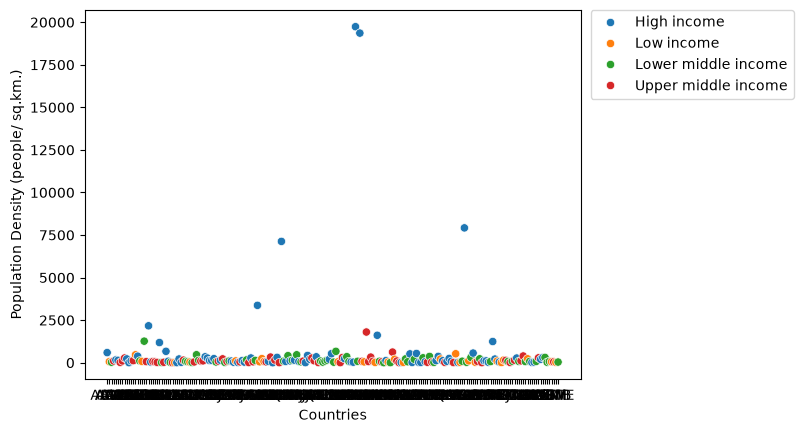

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.scatterplot(data=df_clean, x=df_clean.index, y="2020", hue='IncomeGroup')
lg = plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
tmp = ax.set_xlabel('Countries')
# tmp = ax.set_ylabel('Population Density (sq.km.)')
tmp = ax.set_ylabel('Population Density (people/ sq.km.)')

12-B. Based on the visualization above, briefly discuss your observation on the issue to investigate. If the visualization does not have any meaningful information, suggest another way of transforming data and/or an alternate type of visualization. (You do not need to create another visualization with code here.)

We see a few outliers in population density, most of which are high-income countries. The other countries, including the remaining high-income countries, are clustered at the bottom of the plot because their population densities are lower. A logarithmic scale would help with this problem. We might group the countries into four income tiers and use a boxplot to compare their distributions.

We might also try to restore some of the country rows we dropped. Those missing only a few years of data could potentially be filled using interpolation. For rows missing `Region` or `IncomeGroup`, we could look up the classifications, while excluding aggregate rows that do not represent individual countries. The wealth of the nation could change drastically in the span of 60 years, eg. South Korea. Finally, this plot only shows 2020, so we should explore other years as well. 

13. To prepare this dataset for further exploration and visualization, we should tidy it up. Similar to what we have done in class, create a data dictionary for the new dataset.

| Variable | Data type | Description | Units / possible values |
|---|---|---|---|
| `Country Code` | Text | Three-letter World Bank code identifying the country or economy. | For example, `THA` for Thailand. |
| `Region` | Categorical text | Geographic region assigned to the country or economy in the supplied metadata. | For example, `East Asia & Pacific`. |
| `IncomeGroup` | Categorical text | Income classification from the supplied World Bank metadata. | `Low income`, `Lower middle income`, `Upper middle income`, or `High income`. |
| `Year` | Integer | Year corresponding to the population and land-area measurements. | 1961–2020 in the cleaned dataset. |
| `PopulationDensity` | Decimal number | Total population divided by land area for the same country or economy and year. | People per square kilometre (people/km²). |

14. Tidy up this dataset accordingly.

In [13]:
df_tidy = df_clean.reset_index().melt(
    id_vars=["Country Code", "Region", "IncomeGroup"],
    var_name="Year",
    value_name="PopulationDensity",
)
df_tidy["Year"] = df_tidy["Year"].astype(int)
df_tidy

,Country Code,Region,IncomeGroup,Year,PopulationDensity
0,ABW,Latin America & Caribbean,High income,1961,307.966667
1,AFG,South Asia,Low income,1961,14.058547
2,AGO,Sub-Saharan Africa,Lower middle income,1961,4.436874
3,ALB,Europe & Central Asia,Upper middle income,1961,60.576642
4,AND,Europe & Central Asia,High income,1961,30.591489
...,...,...,...,...,...
12475,WSM,East Asia & Pacific,Lower middle income,2020,71.370504
12476,YEM,Middle East & North Africa,Low income,2020,56.491786
12477,ZAF,Sub-Saharan Africa,Upper middle income,2020,48.890593
12478,ZMB,Sub-Saharan Africa,Low income,2020,24.729894


## AI Use Log and Reflection

**AI tool(s) used (name + version):** GPT-6-Astra via codex

| Task / variable | Exact prompt | What the AI suggested (1–2 lines) | What you used, changed, or rejected, and why | How you verified it |
|---|---|---|---|---|
| 9| "task 9, how do i proceed as i get a boolean matrix via `null_counts_after = df_merged.isna()`. (the model already got prompt earlier to only give hints and explanation"|  you can just use `.sum()`, it'll turned that dataframe into a series|  `.sum()`|  check pandas documentation, then run it|
| 14| I supposed I'll have to use `.melt()` for task 14, can you explain how to use it? | it provide explanation and examples| implement the solution|  I already read the official documentation prior to asking the model|

### Discussion / Reflection

**Chosen path (A or B):** A

- What was your strategy for using AI (when did you turn to it, and what kinds of questions did you ask)?
> I let codex access my entire codebase from the start, point it to where we're working on, and prompt it to only give hints and explanation, and to never write to file. 

- Which prompt helped you learn the most, and why was it effective?
> `.melt()`, codex gives a lot of examples that match the task's objective, just with different scenario/ vairable.

- Did the AI ever give you something wrong, outdated, or against the task rules? How did you notice?
> for the first part of this assignment, no. It was a short task and there usually be only one correct answer. I didn't have the model check task 12-B, which if it did, it probably issued a lot of correction. 

- What will you do differently when using AI in the rest of the course?
> nothing.

---